## Start here — Google Colab
Upload this entire unzipped folder to **My Drive**, open this notebook with Google Colaboratory, and choose **Runtime → Run all**. Approve the Drive connection when prompted. The next cell finds the course and prepares its dependencies automatically. No path editing is needed.
Run notebooks **00 → 01 → 02 → 03 → 04**. Use a fresh runtime for this course. CPU is sufficient. The first setup can take a few minutes. Results are saved in the same Drive folder.


In [ ]:
# Connect Drive and prepare this course automatically before importing lesson libraries.
from pathlib import Path
import os
import sys
import json
import subprocess
import importlib.metadata as package_metadata

COURSE_ID = 'ground-truth-gym-l3-4.0'
MARKER = 'COURSE_PACKAGE.json'
try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    drive.mount('/content/drive')
    search_root = Path('/content/drive/MyDrive')
else:
    search_root = Path.cwd()


def find_course(root):
    matches = []
    for directory, subfolders, files in os.walk(root):
        subfolders[:] = [name for name in subfolders if not name.startswith('.') and name not in {'node_modules', '__pycache__'}]
        if MARKER in files:
            marker = Path(directory) / MARKER
            if json.loads(marker.read_text()).get('course_id') == COURSE_ID:
                matches.append(Path(directory))
                subfolders[:] = []
    if len(matches) != 1:
        raise RuntimeError('Keep one unzipped GroundTruth_Gym_L3 folder in My Drive, then run this cell again. Found: ' + str(len(matches)))
    return matches[0]

# Reuse this notebook's local directory, or discover its uploaded Drive folder.
local_marker = Path.cwd() / MARKER
if drive is None and local_marker.exists() and json.loads(local_marker.read_text()).get('course_id') == COURSE_ID:
    course_root = Path.cwd()
else:
    course_root = find_course(search_root)
os.chdir(course_root)

requirements = (course_root / 'requirements-colab.txt').read_text().splitlines()
requirements = [line.strip() for line in requirements if line.strip() and not line.startswith('#')]
if drive is not None:
    # Install to a runtime-local directory before any scientific library imports.
    # Keep Google Colab's own packages and Drive integration unchanged.
    dependency_dir = Path('/content/groundtruth_gym_dependencies')
    stamp = dependency_dir / 'course_requirements.json'
    if not stamp.exists() or json.loads(stamp.read_text()) != requirements:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', '--upgrade', '--target', str(dependency_dir), *requirements])
        stamp.write_text(json.dumps(requirements))
    sys.path.insert(0, str(dependency_dir))
    # A fresh course runtime avoids mixing pre-imported binary library versions.
    for distribution, module in [('numpy', 'numpy'), ('pandas', 'pandas'), ('scipy', 'scipy'), ('scikit-learn', 'sklearn'), ('matplotlib', 'matplotlib'), ('joblib', 'joblib')]:
        expected = next(line.split('==')[1] for line in requirements if line.startswith(distribution + '=='))
        loaded = sys.modules.get(module)
        if loaded is not None and getattr(loaded, '__version__', expected) != expected:
            raise RuntimeError('Please select Runtime > Disconnect and delete runtime, reconnect, and Run all. No path or package configuration is needed.')

for item in requirements:
    distribution, expected = item.split('==')
    actual = package_metadata.version(distribution)
    if actual != expected:
        raise RuntimeError(f'{distribution}: expected {expected}, found {actual}. Use a fresh Colab runtime and run this first cell.')

# Use a consistent single-thread execution policy across notebook runtimes.
for variable in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[variable] = '1'
print('Course ready:', course_root.name)
print('Data and results persist in your course folder. Run notebooks 00 → 01 → 02 → 03 → 04.')


# 02 — Basic modeling: build and compare a purchase ranking

**Goal:** Use decision-time member information to rank future PT buyers, then compare the ranking with the staff rule.

**Before you start:** Run notebook 01. Work from this Current folder with gym_case_data next to the notebook.

| What goes in | What comes out |
|---|---|
| Clean activity/profile/store tables and decision-aligned observations | One member-level feature table |
| Complete January outcomes | Training-fitted Logistic and GBM pipelines |
| Complete February outcomes | A comparison at the promotion selection fraction |
| Fixed feature definitions and settings | A saved handoff for advanced modeling |

### Follow the seven steps

| Section | Main question |
|---|---|
| MOD-01 | What are X, y and the business decision? |
| MOD-02 | How do event rows become one member row? |
| MOD-03 | Which data learns, compares and evaluates? |
| MOD-04 | What does preprocessing do to a member? |
| MOD-05 | How do Logistic and GBM learn from the same inputs? |
| MOD-06 | Which method finds more buyers at the actual selection budget? |
| MOD-07 | What must be saved for the next notebook? |

**Reading pattern:** Read the question and plan → run the annotated cell → inspect its output → read the takeaway.

**Scope:** All eligible PT histories remain included. Scores estimate new purchase likelihood under historical conditions. Notebook 03 develops feature alternatives and evaluates April; this notebook compares the full-feature baselines on February.

## MOD-01 — Define what X, y and the decision mean

### The question
What information should the model receive, and what should it predict?

| Item | Definition in this case |
|---|---|
| **One observation** | One eligible member at one decision time |
| **X: model inputs** | 12 numeric + 6 categorical candidates known at that decision |
| **y=1** | A new valid PT package purchase in the following 30 days, reconciled at day 33 |
| **y=0** | Complete payment window with no qualifying new purchase |
| **Unknown y** | Pending or incomplete outcome; excluded from supervised fitting |
| **Business use** | Score 1,200 eligible members; business selects the top 1,000 |

### What the next cell does
1. Imports the libraries and defines input/output paths.
2. Sets the fixed model parameters and the 5/6 promotion fraction.
3. Loads notebook 01's saved tables and defines the candidate feature contract.

**Why these candidates?** EDA supports testing engagement, PT history, profile and store context together. This basic comparison starts with all 18 checked inputs.

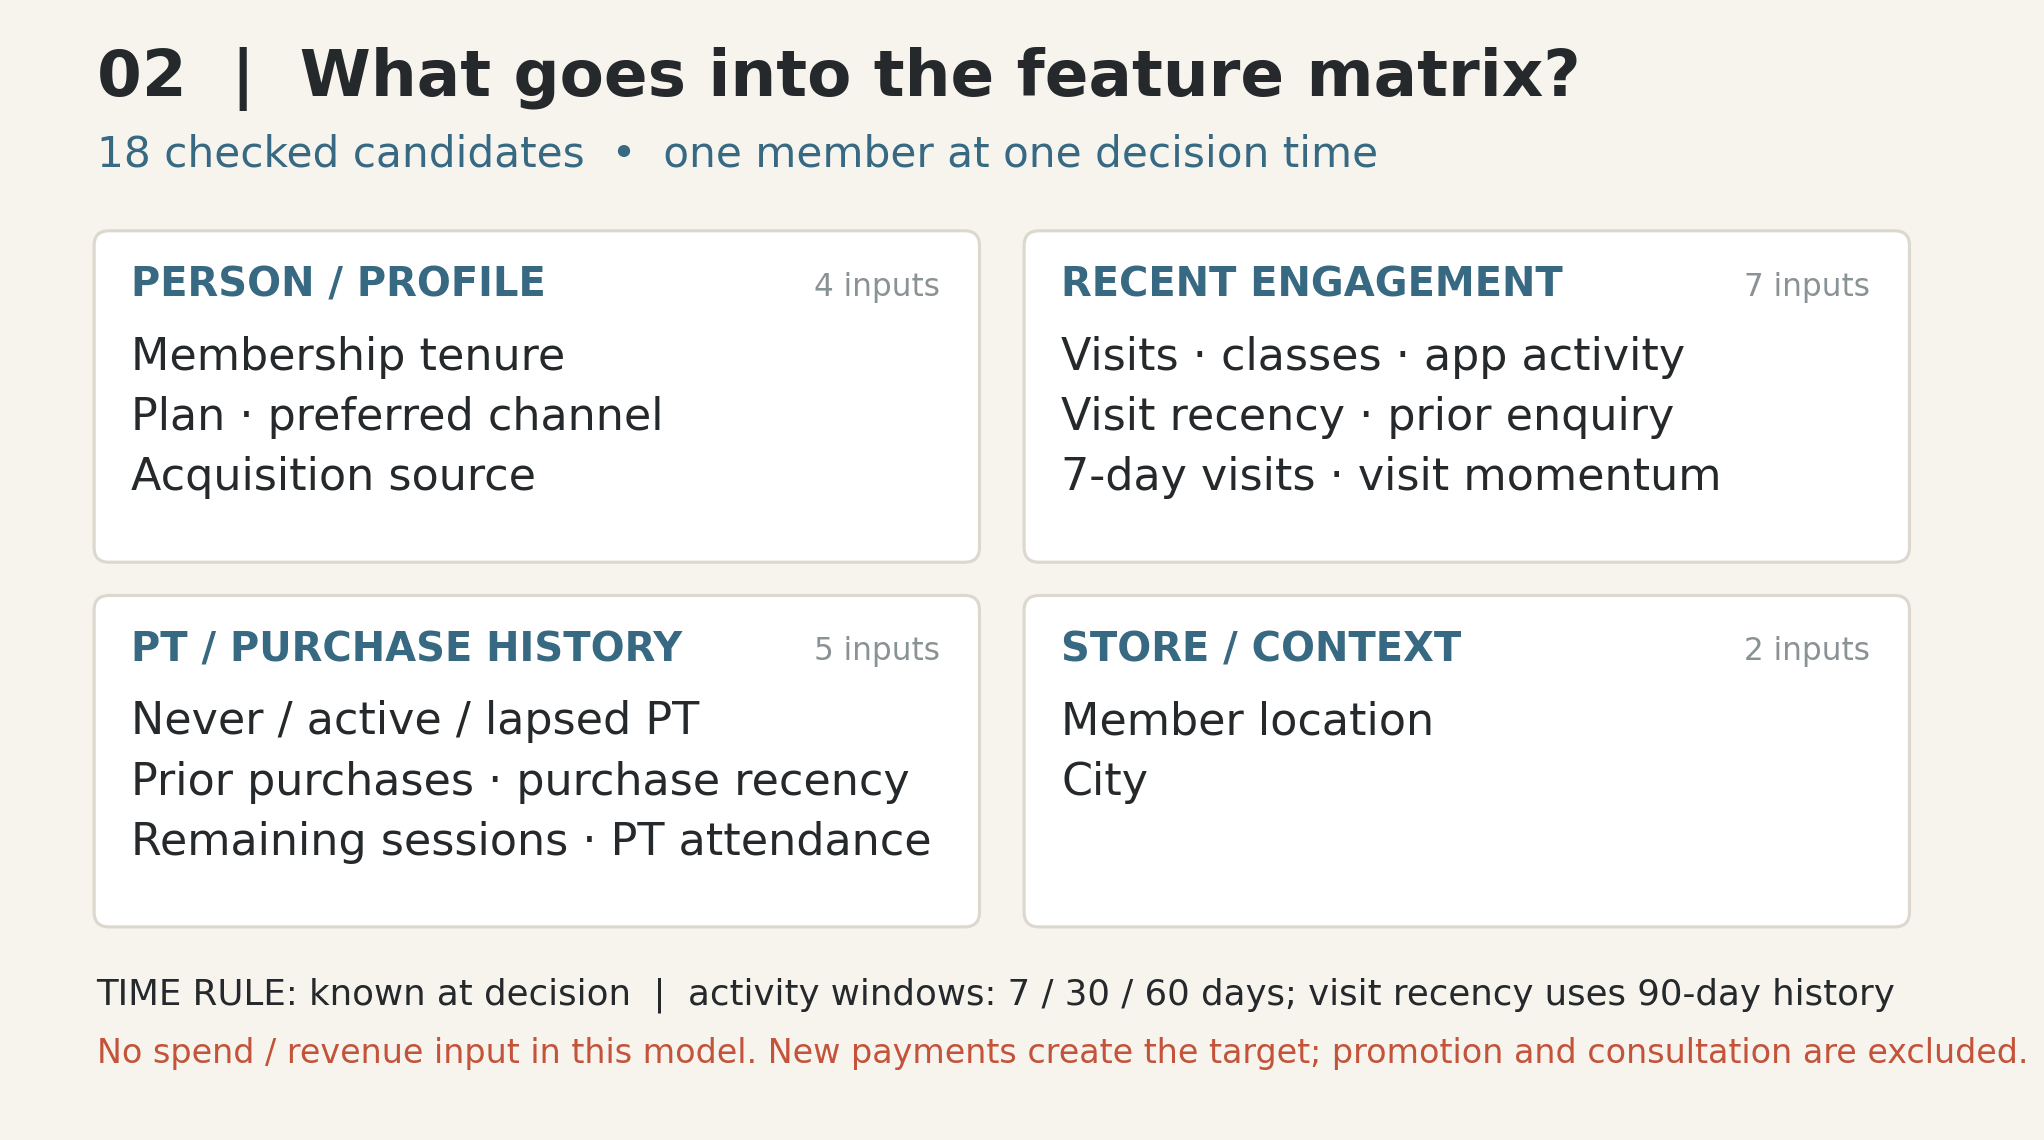

### What to look for
Inspect each feature's **source, time window and meaning**. Promotion and consultation records remain outside X; they explain operations rather than supply predictors.

In [ ]:
# Import libraries: file paths, tables, plots, model pipelines and saved artifacts.
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss
import sklearn
import joblib


# Input and output paths: run from Current; notebook01 has already written these files.
DATA_DIR = Path('gym_case_data')
MODEL_DIR = DATA_DIR / 'model'
MODEL_DIR.mkdir(exist_ok=True)
assert (DATA_DIR / 'observations.csv').exists(), 'Run notebook 01 first.'
manifest = json.loads((DATA_DIR / 'manifest.json').read_text())


# Reproducibility and business budget: seed fixes random choices;5/6 is the promotion fraction.
SEED = manifest['seed']
CONTACT_FRACTION = 5 / 6


# Logistic parameters: smaller C means stronger regularization; max_iter is the solver limit.
LOGISTIC_C = 0.3
MAX_ITERATIONS = 1000


# GBM parameters: limit the number, size and learning speed of the small trees.
GBM_TREES = 50
GBM_LEARNING_RATE = 0.05
GBM_MAX_DEPTH = 2
GBM_MIN_LEAF = 20


# Feature routing: measurements/counts go to the numeric transformer; labels/IDs stay outside X.
NUMERIC_FEATURES = ['tenure_days', 'checkins_30d', 'classes_30d', 'app_views_30d', 'days_since_checkin', 'inquiry_60d', 'checkins_7d', 'checkin_momentum', 'pt_sessions_30d', 'prior_pt_purchases', 'days_since_pt_purchase', 'remaining_pt_sessions']


# Categorical feature handling: these strings will be imputed and one-hot encoded later.
CATEGORICAL_FEATURES = ['plan_type', 'preferred_channel', 'acquisition_source', 'location_id', 'city', 'pt_relationship']
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
print('[INFO]', {'data_version': manifest['data_version'], 'seed': SEED, 'contact_fraction': CONTACT_FRACTION,
                 'logistic_C': LOGISTIC_C, 'max_iterations': MAX_ITERATIONS,
                 'gbm_trees': GBM_TREES, 'gbm_min_leaf': GBM_MIN_LEAF})


# Load the observation table from01; parse timestamps into comparable UTC values.
observations = pd.read_csv(DATA_DIR / 'observations.csv')
for column in observations:
    if column.endswith('_at') or column in ['decision_time', 'outcome_end', 'payments_complete_through']:
        observations[column] = pd.to_datetime(observations[column], utc=True, format="mixed")


# Load clean events; event_time and available_at support the two-clock feature cutoff.
activities = pd.read_csv(DATA_DIR / 'clean/activity_events.csv')
for column in ['event_time', 'available_at']:
    activities[column] = pd.to_datetime(activities[column], utc=True, format="mixed")


# Store context is a static dimension in this synthetic fixture.
locations = pd.read_csv(DATA_DIR / 'clean/locations.csv')


# Feature definitions: document sources/windows before deriving measurements.
feature_contract = pd.DataFrame([
    ('tenure_days', 'member signup', 'known signup → decision', 'membership age in days'),
    ('checkins_30d', 'activity_events', '[decision − 30d, decision)', 'known check-in count'),
    ('classes_30d', 'activity_events', '[decision − 30d, decision)', 'known class count'),
    ('app_views_30d', 'activity_events', '[decision − 30d, decision)', 'known app-view count'),
    ('days_since_checkin', 'activity_events', 'supplied 90-day history', 'recency; missing if no known visit'),
    ('inquiry_60d', 'activity_events', '[decision − 60d, decision)', 'any known enquiry'),
    ('checkins_7d / checkin_momentum', 'activity_events', '7d versus preceding 23d', 'recent visits and difference in daily visit rates'),
    ('pt_sessions_30d', 'activity_events', '[decision - 30d, decision)', 'known recent PT attendance'),
    ('prior_pt_purchases / days_since_pt_purchase / remaining_pt_sessions', 'decision-time CRM snapshot', 'strictly pre-decision purchase history', 'prior purchase count, recency and remaining balance'),
    ('pt_relationship', 'decision-time CRM snapshot', 'at decision', 'never_pt, active_pt or lapsed_pt; no exclusion'),
    ('plan_type / preferred_channel / acquisition_source', 'member decision snapshot', 'at decision', 'string profile fields'),
    ('location_id / city', 'snapshot and location dimension', 'at decision', 'store context')],
    columns=['feature', 'source', 'window', 'meaning'])


# Inspect and save the contract so later notebooks can trace each input.
display(feature_contract)
feature_contract.to_csv(MODEL_DIR / 'feature_contract.csv', index=False)

### Takeaway — MOD-01

**You now have a defined X/y contract and visible configuration.** Candidate inputs describe the member before the decision; the target describes a new purchase afterward.

**Before moving on:** Explain in your own words how this output supports the next step.

## MOD-02 — Turn known event rows into one member row

### The question
How can many activity rows describe one member without multiplying the modeling examples?

### The plan
- **Keep known events:** event_time < decision_time and available_at <= decision_time.
- **Summarize activity:** counts over 7/30 days, prior enquiry over 60 days, and visit recency from the supplied history.
- **Add context:** tenure and decision-time PT/profile facts, then the static fixture's store dimension.
- **Preserve the unit:** one member-decision row, with checked join cardinality.

**Missing has meaning:** No known check-in gives missing visit recency. A never-buyer has no previous purchase date. Keep these cases for later imputation and missingness indicators.

### What to look for
Compare the displayed raw events with the example feature row. Check the printed **row counts, unmatched identities and duplicate keys**. The event summary should explain the member's measurements.

In [ ]:
# Keep decisions that have occurred by extraction; planned future decisions lack reconstructible history.
entered_observations = observations.loc[observations.decision_time.le(pd.Timestamp(manifest['extracted_at']))].copy()
print(f'[CHECK] Entered snapshot filter: {len(observations)} to {len(entered_observations)} members (dropped {len(observations)-len(entered_observations)} planned future decisions).')


# Aggregate one measurement dictionary per member; event rows do not become extra examples.
feature_rows = []
for number, member in enumerate(entered_observations.itertuples(index=False), start=1):

    # Check that the profile snapshot and prior-history dates are valid at this decision.
    assert member.snapshot_available_at <= member.decision_time
    assert member.signup_at <= member.decision_time
    assert pd.isna(member.last_pt_purchase_at) or member.last_pt_purchase_at < member.decision_time
    assert member.eligible

    # Profile and remaining-session values are fixture decision snapshots.
    # A real deployment requires effective-time/version history for each mutable field.
    # Find this member's events through the unique identity key.
    member_events = activities.loc[activities.uid.eq(member.uid)]

    # Two clocks: occurrence before the decision AND source availability by the decision.
    known_events = member_events.loc[member_events.event_time.lt(member.decision_time)
                                     & member_events.available_at.le(member.decision_time)]

    # Apply30-day and60-day windows only after removing unavailable/future events.
    recent_events = known_events.loc[known_events.event_time.ge(member.decision_time - pd.Timedelta(days=30))]
    checkins = known_events.loc[known_events.event_type.eq('checkin')]
    enquiries = known_events.loc[known_events.event_type.eq('pt_inquiry')
                                 & known_events.event_time.ge(member.decision_time - pd.Timedelta(days=60))]

    # Short-term activity and momentum: compare last7-day rate with the preceding23-day rate.
    checkins_7d = int((checkins.event_time >= member.decision_time-pd.Timedelta(days=7)).sum())
    checkins_30d = int(recent_events.event_type.eq('checkin').sum())

    # Build numeric features; missing recency stays NaN when no relevant prior event exists.
    feature_rows.append({'checkins_7d': checkins_7d,
                         'checkin_momentum': checkins_7d/7 - (checkins_30d-checkins_7d)/23,
                         'pt_sessions_30d': int(recent_events.event_type.eq('pt_session').sum()),
                         'days_since_pt_purchase': (member.decision_time-member.last_pt_purchase_at).total_seconds()/86400 if pd.notna(member.last_pt_purchase_at) else np.nan,
                         'member_id': member.member_id,
                         'tenure_days': (member.decision_time - member.signup_at).days,
                         'checkins_30d': int(recent_events.event_type.eq('checkin').sum()),
                         'classes_30d': int(recent_events.event_type.eq('group_class').sum()),
                         'app_views_30d': int(recent_events.event_type.eq('app_view').sum()),
                         'days_since_checkin': (member.decision_time - checkins.event_time.max()).total_seconds()/86400 if len(checkins) else np.nan,
                         'inquiry_60d': int(len(enquiries) > 0)})
    if number % 500 == 0 or number == len(entered_observations):
        print(f'[INFO] Feature construction: {number}/{len(entered_observations)} members processed')


# Attach aggregates once per member; validate guards against accidental row multiplication.
feature_table = entered_observations.merge(pd.DataFrame(feature_rows), on='member_id', validate='one_to_one')


# Add store/city context with a many-to-one dimension join.
feature_table = feature_table.merge(locations, on='location_id', how='left', validate='many_to_one')
assert feature_table.city.notna().all() and feature_table.member_id.is_unique
assert not feature_table.duplicated(['member_id', 'decision_time']).any()


# locations is a static fixture dimension; changing real-world store context requires an as-of join.
print(f'[CHECK] Feature/profile joins: {len(entered_observations)} input → {len(feature_table)} output; unmatched 0; duplicated member keys 0; city missingness introduced 0.')


# Save a disk handoff, including audit columns and label readiness alongside predictors.
feature_table.to_csv(DATA_DIR / 'member_features.csv', index=False)


# Audit one training row against its underlying known events.
example = feature_table.loc[feature_table.campaign_id.eq('pilot_train')].iloc[0]
example_known = activities.loc[activities.uid.eq(example.uid) & activities.event_time.lt(example.decision_time)
                                & activities.available_at.le(example.decision_time)]
display(example_known.sort_values('event_time').tail(6))
display(feature_table.loc[feature_table.member_id.eq(example.member_id), ['member_id', 'decision_time'] + FEATURE_COLUMNS])


# Verify the displayed30-day check-in feature independently from its raw event rows.
assert int((example_known.event_type.eq('checkin') & example_known.event_time.ge(example.decision_time-pd.Timedelta(days=30))).sum()) == example.checkins_30d

### Takeaway — MOD-02

**Each entered member-decision now has one auditable feature row.** Known events are aggregated before joining. The saved member_features.csv carries both historical and upcoming rows; later filtering determines which can train.

**Before moving on:** Explain in your own words how this output supports the next step.

## MOD-03 — Reserve future periods before learning transformations

### The question
How will we distinguish learning from evidence on later members?

| Group | Decision period | Complete members | Role |
|---|---|---:|---|
| **Training** | January |350 | Fit preprocessing and models; develop candidate features |
| **Validation** | February |150 | Compare candidates and guide development |
| **Later evaluation** | April |125 | Evaluate the approach finalized in notebook 03 |
| **Upcoming** | June |1,200 | Score using saved training state; outcomes unknown |

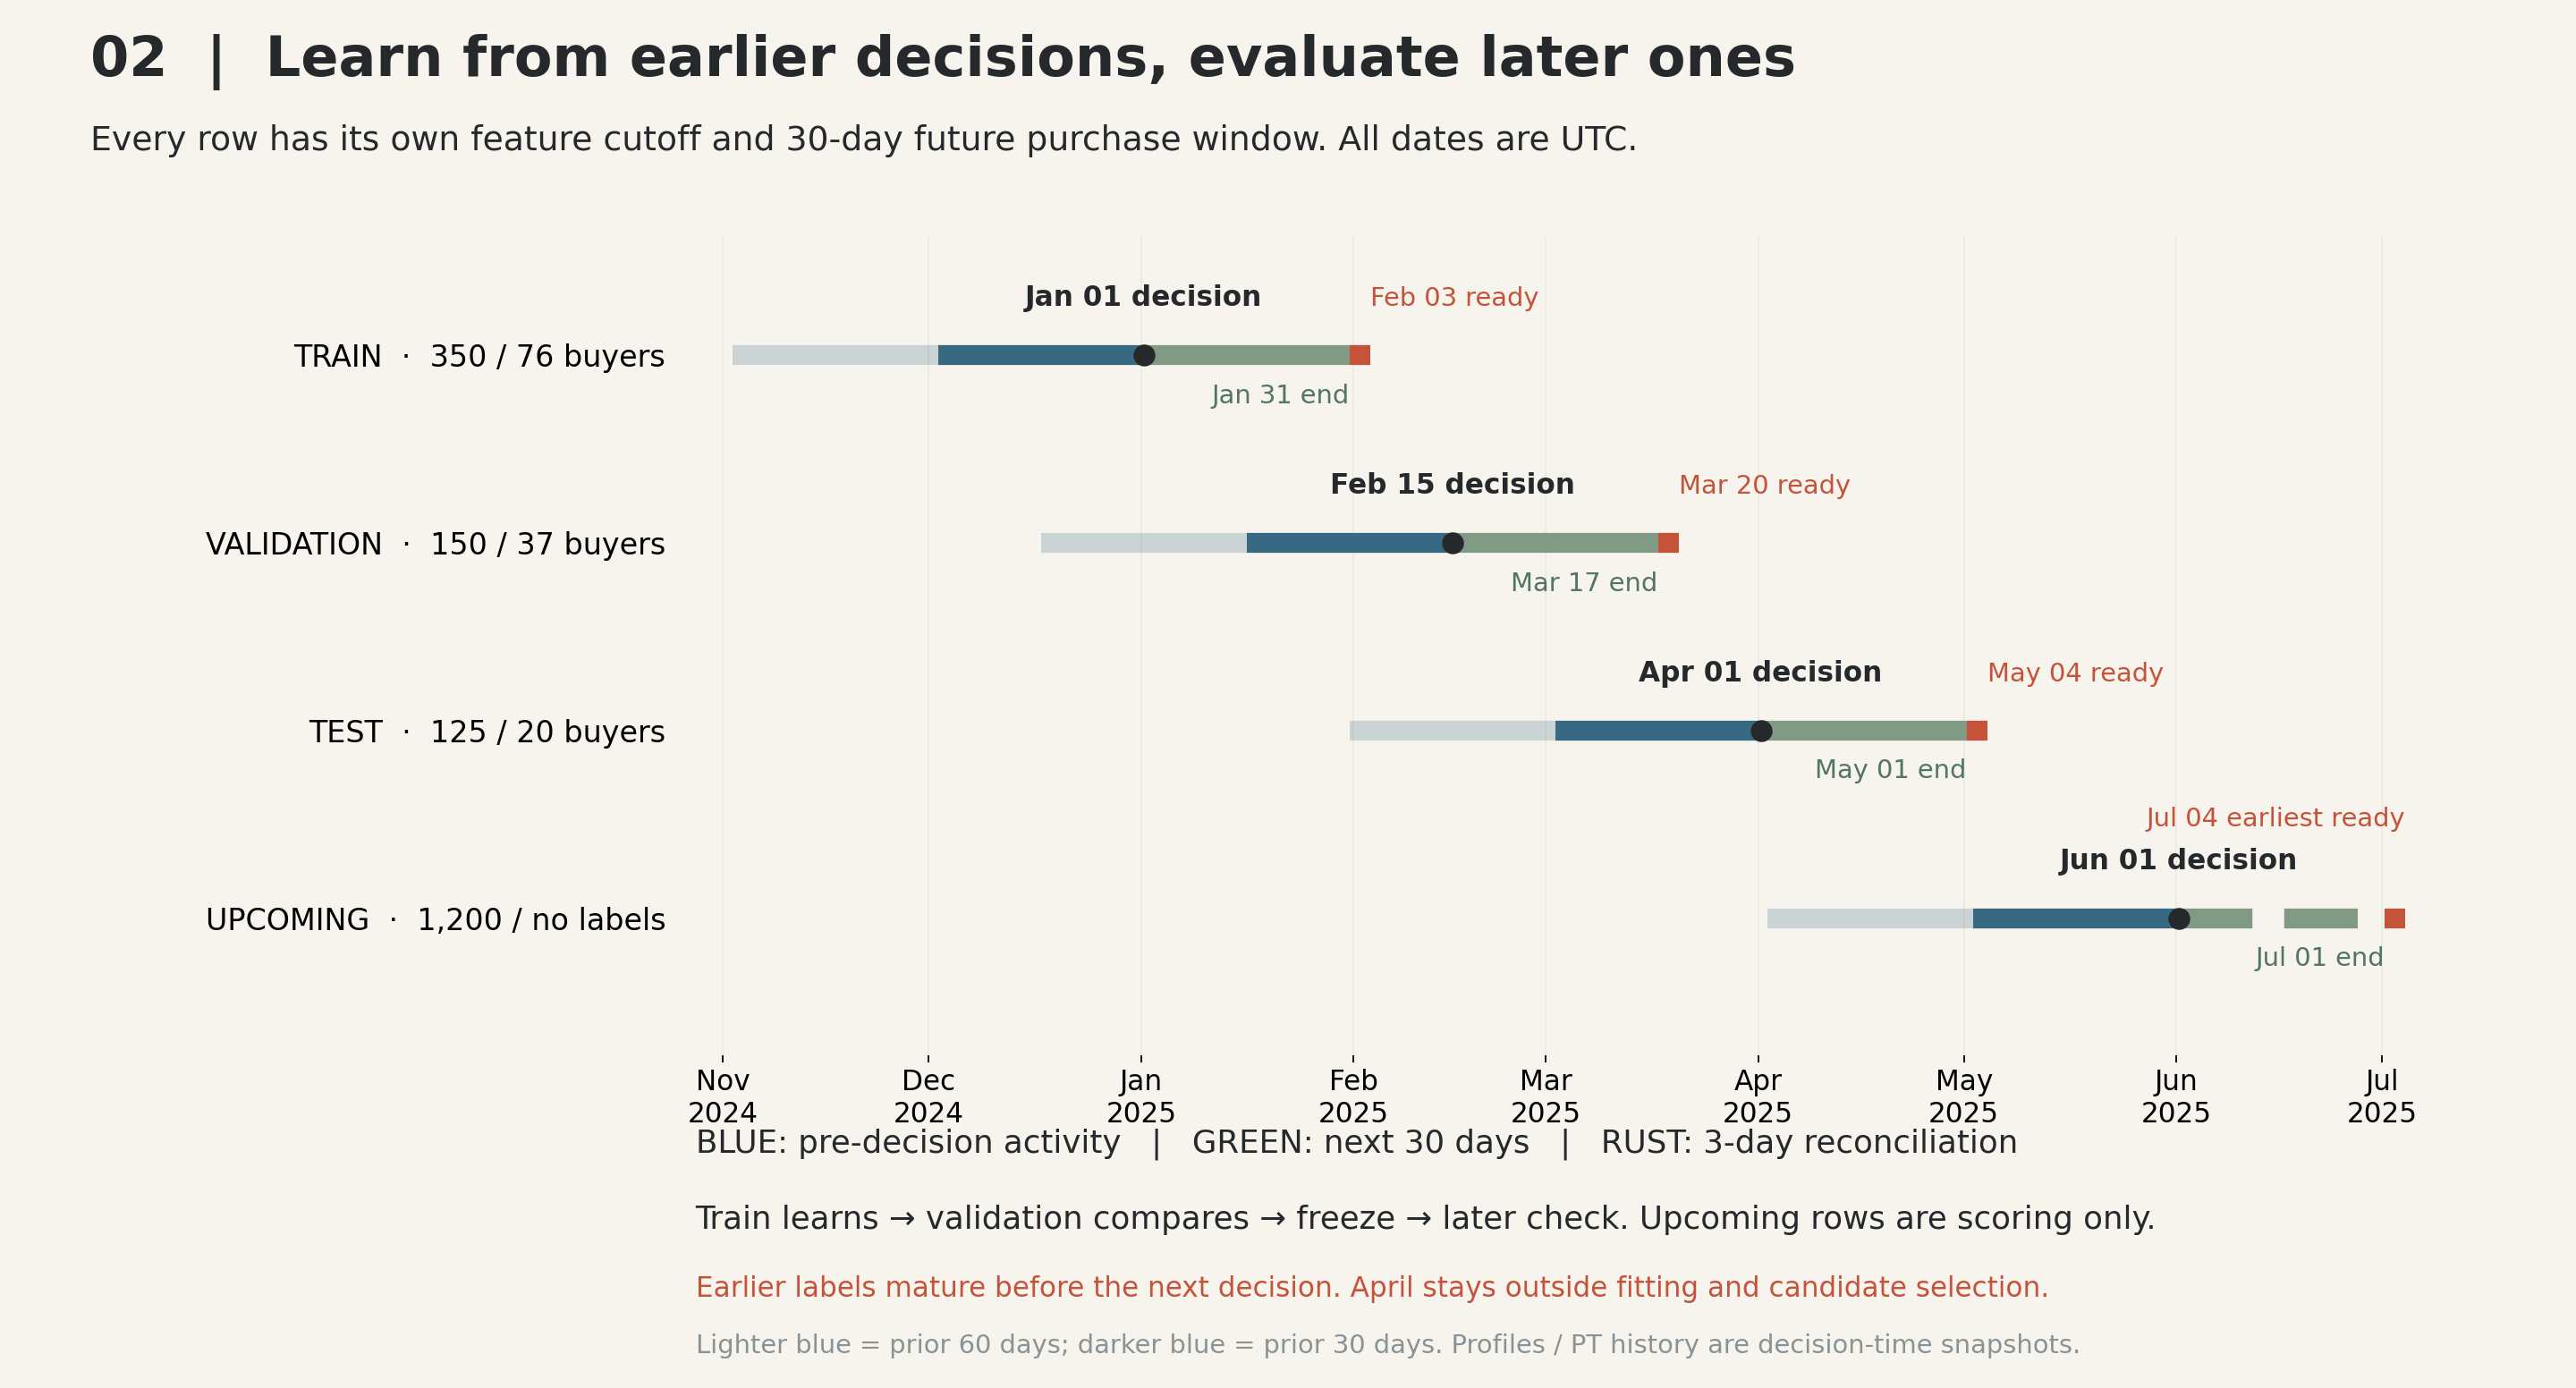

### The checks
1. Keep only complete labels for supervised learning.
2. Confirm each earlier cohort's labels mature before the next decision.
3. Check member identities across groups and payment coverage.
4. Create X_train/y_train and X_validation/y_validation.

### What to look for
Read the calendar and **training feature-readiness table**. Counts350/150/125 describe the chronological groups, not a cleaning attrition funnel. Training contains 76 buyers; validation contains 37.

In [ ]:
# Supervised learning uses complete labels; unknown outcomes remain unknown.
complete = feature_table.loc[feature_table.label_status.eq('complete')].copy()


# Assign chronological roles by campaign decision period, rather than random row sampling.
train = complete.loc[complete.campaign_id.eq('pilot_train')].copy()
validation = complete.loc[complete.campaign_id.eq('pilot_validation')].copy()
test = complete.loc[complete.campaign_id.eq('pilot_test')].copy()
upcoming = feature_table.loc[feature_table.campaign_id.eq('upcoming')].copy()


# Build a readable calendar: feature lookbacks, decisions, outcomes and label maturity.
split_rows = []
for name, group in [('train', train), ('validation', validation), ('test', test), ('upcoming', upcoming)]:
    campaign_id = group.campaign_id.iloc[0]
    nominal = int(feature_table.campaign_id.eq(campaign_id).sum())
    print(f'[CHECK] {name} usable population: {nominal} to {len(group)} members (excluded {nominal-len(group)}; inspect time/coverage reasons).')
    split_rows.append({'split': name, 'members': len(group), 'feature_30d_start': group.decision_time.min()-pd.Timedelta(days=30),
                       'feature_60d_start': group.decision_time.min()-pd.Timedelta(days=60),
                       'decision_time': group.decision_time.min(), 'first_delivery_min': group.delivered_at.min(),
                       'first_delivery_max': group.delivered_at.max(), 'outcome_end_min': group.outcome_end.min(),
                       'outcome_end_max': group.outcome_end.max(), 'label_ready_min': group.label_ready_at.min(),
                       'label_ready_max': group.label_ready_at.max()})
split_calendar = pd.DataFrame(split_rows)
display(split_calendar)
split_calendar.to_csv(MODEL_DIR / 'split_calendar.csv', index=False)


# Earlier outcomes must mature before the next cohort decision.
assert train.label_ready_at.max() < validation.decision_time.min()
assert validation.label_ready_at.max() < test.decision_time.min()
assert test.label_ready_at.max() < upcoming.decision_time.min()


# Verify that this fixture uses different members across the four roles.
member_sets = [set(group.member_id) for group in [train, validation, test, upcoming]]
assert all(member_sets[left].isdisjoint(member_sets[right]) for left in range(4) for right in range(left+1, 4))


# Verify extraction readiness and payment coverage before using historical labels.
assert complete.label_ready_at.le(pd.Timestamp(manifest['extracted_at'])).all()
assert complete.payments_complete_through.ge(complete.label_ready_at).all()
assert feature_table.loc[feature_table.label_status.ne('complete'), 'label'].isna().all()
assert upcoming.label.isna().all()


# X contains only declared predictors; y is the complete binary purchase outcome.
X_train, y_train = train[FEATURE_COLUMNS], train.label.astype(int)


# Training-only readiness audit: missing counts and variation in the candidate inputs.
quality = pd.DataFrame({'feature': FEATURE_COLUMNS, 'training_missing': X_train.isna().sum().values,
                       'training_distinct': X_train.nunique().values})
display(quality)
quality.to_csv(MODEL_DIR / 'candidate_feature_readiness.csv', index=False)
print('[RESULT] Train / validation / test:', len(train), len(validation), len(test))
print('[RESULT] Training / validation positives:', int(y_train.sum()), int(validation.label.sum()))


# Reserve February inputs/outcomes for comparison; no fit happens on these rows.
X_validation, y_validation = validation[FEATURE_COLUMNS], validation.label.astype(int)


# Test targets remain unused until the candidate has been frozen below.

### Takeaway — MOD-03

**Learning and evaluation have different data roles.** January learns; February compares; April is reserved for03; upcoming outcomes remain unknown. Readiness/identity checks protect that separation.

**Before moving on:** Explain in your own words how this output supports the next step.

## MOD-04 — Inspect what preprocessing does to a member

### The question
How do mixed measurements and categories become consistent numerical model inputs?

| Input type | Handling | What is learned from training |
|---|---|---|
| **Numeric missing values** | Median imputation + missing indicators for fields missing during fitting | Medians and indicator fields |
| **Numeric units** | Standardization | Means and scales after imputation |
| **Missing categories** | Replace with unknown | Fixed rule |
| **Categories** | One-hot encoding | Training category vocabulary |

### The plan
Use a ColumnTransformer to send numeric and categorical columns through their own pipelines. Fit a **preview on training only**, then inspect its learned values and an example row. The two models receive fresh clones of this recipe.

**Later inputs:** Validation, April and upcoming members use the fitted rules. A new nonmissing category maps to an all-zero encoded block for that field.

### What to look for
Compare **original columns → transformed named columns**. Locate the imputed value and missing indicator. Numeric indicators are scaled along with the numeric measurements in this implementation. GBM does not require scaling, but uses the same initial recipe for this comparison.

In [ ]:
# Numerical feature handling: learn medians/indicators, then scale the imputed measurements.
numeric_transform = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                              ('scale', StandardScaler())])


# Categorical feature handling: fill missing strings and learn training category columns.
category_transform = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='unknown')),
                               ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])


# ColumnTransformer routes each declared feature family to its own preparation pipeline.
preprocessor = ColumnTransformer([('numeric', numeric_transform, NUMERIC_FEATURES),
                                  ('categorical', category_transform, CATEGORICAL_FEATURES)])


# Fit a separate training-only preview so we can inspect the transformation before modeling.
preview = clone(preprocessor)
transformed_train = preview.fit_transform(X_train)


# Name the expanded columns; one category can become several indicator columns.
transformed_names = preview.get_feature_names_out()


# Inspect the values learned from training, not statistics recomputed on validation.
training_statistics = pd.DataFrame({'feature': NUMERIC_FEATURES,
    'median': preview.named_transformers_['numeric'].named_steps['impute'].statistics_,
    'mean_after_imputation': preview.named_transformers_['numeric'].named_steps['scale'].mean_[:len(NUMERIC_FEATURES)],
    'scale': preview.named_transformers_['numeric'].named_steps['scale'].scale_[:len(NUMERIC_FEATURES)]})
display(training_statistics.round(3))


# Choose an example with missing visit recency, when available, to show imputation explicitly.
missing_rows = X_train.index[X_train.days_since_checkin.isna()]
example_index = missing_rows[0] if len(missing_rows) else X_train.index[0]
example_position = X_train.index.get_loc(example_index)
display(X_train.loc[[example_index]])


# Display the same member after transformation, with the numerical column names.
transformed_example = pd.DataFrame({'transformed_feature': transformed_names, 'value': transformed_train[example_position]})
display(transformed_example.round(3))
print('[RESULT] Original columns:', X_train.shape[1], '| expanded columns:', transformed_train.shape[1])


# Save the inspected statistics/example as supporting evidence.
training_statistics.to_csv(MODEL_DIR / 'preprocessing_statistics.csv', index=False)
transformed_example.to_csv(MODEL_DIR / 'transformed_example.csv', index=False)

### Takeaway — MOD-04

**Preprocessing is fitted state, not just formatting.** Inspect the example to see imputation, indicators, scaling and encoding, then reuse training-fitted rules for later members.

**Before moving on:** Explain in your own words how this output supports the next step.

## MOD-05 — Fit Logistic Regression and GBM with all candidate features

### The question
Does a more flexible relationship improve the ranking compared with a simpler additive model?

| Candidate | How it combines information | Complexity control |
|---|---|---|
| **Logistic Regression** | Additive weighted inputs, converted to probability | Regularization: C=0.3 |
| **GBM** | Sequential small trees with thresholds/interactions |50 trees, learning rate 0.05, depth 2, minimum 20 members per leaf |

### Make the comparison consistent
Both use the **same 350 training members, labels,18 inputs and preprocessing recipe**. Each fits its own preprocessing clone. Settings are fixed for this experiment.

### What to look for
The final check reconstructs one Logistic probability from its intercept and weights, then compares it with predict_proba. This connects the fitted calculation to the probability returned by the complete pipeline.

In [ ]:
# Logistic pipeline: a fresh preprocessing clone plus an additive regularized classifier.
logistic_model = Pipeline([('features', clone(preprocessor)),
                           ('model', LogisticRegression(C=LOGISTIC_C, max_iter=MAX_ITERATIONS, random_state=SEED))])


# GBM pipeline: the same recipe plus fixed, limited-depth boosted trees.
gbm_model = Pipeline([('features', clone(preprocessor)),
                      ('model', GradientBoostingClassifier(n_estimators=GBM_TREES, learning_rate=GBM_LEARNING_RATE,
                          max_depth=GBM_MAX_DEPTH, min_samples_leaf=GBM_MIN_LEAF, random_state=SEED))])


# Fit each complete pipeline on January only; fit includes its own imputer/scaler/encoder.
logistic_model.fit(X_train, y_train)
gbm_model.fit(X_train, y_train)


# Reconstruct one Logistic score: transformed row -> weighted log-odds -> probability.
example_vector = logistic_model.named_steps['features'].transform(X_train.loc[[example_index]])[0]
weighted_score = float(logistic_model.named_steps['model'].intercept_[0] + example_vector @ logistic_model.named_steps['model'].coef_[0])


# Check that the manual probability matches predict_proba;[:,1] is the purchase class.
np.testing.assert_allclose(1 / (1 + np.exp(-weighted_score)), logistic_model.predict_proba(X_train.loc[[example_index]])[0, 1])
print('[CHECK] Manual Logistic probability matches the pipeline.')

### Takeaway — MOD-05

**Both candidates have learned from the same training information.** The reconstructed Logistic probability matches the pipeline output. Validation, rather than model complexity, determines the next comparison.

**Before moving on:** Explain in your own words how this output supports the next step.

## MOD-06 — Compare purchase rankings at the promotion fraction

### The question
Which method captures more observed buyers in the list the business would actually select?

**Budget:** floor(n ×5/6). February has150 members, so each list contains125.

**Business baseline:** Known PT enquiry first → earlier signup → member ID. Model lists use purchase probability → member ID.

| Metric | Role in this comparison |
|---|---|
| **Selected buyers / Precision at budget** | Main decision: more buyers in the equally sized list |
| **Average Precision** | Whole-ranking evidence; breaks a main-metric tie |
| Recall and ranking lift | Coverage/enrichment diagnostics; same ordering at fixed population and budget |
| Brier score | Probability-error diagnostic; lower is better |

### The plan
1. Apply the same short metric helper to staff, Logistic and GBM.
2. Predict February probabilities without fitting on February.
3. Compare Precision, then AP, then favor Logistic on an exact tie.

### What to look for
Read **buyers / selected members**, then percentages. The current validation result is staff 31, Logistic 32 and GBM 33 buyers. Logistic has higher AP, while GBM leads at this business cutoff. With37 buyers in one cohort, use the result as development evidence. Ranking lift means enrichment over random selection, not causal promotion lift. AP here is not trapezoidal PR-AUC.

In [ ]:
# Evaluation helper: use the same promotion budget and counts for every method.
def ranking_summary(frame, scores=None):
    """Same population and promotion fraction; descriptive purchase metrics only."""

    # Round down to an integer list size; this budget is unrelated to consultation capacity.
    selected_count = int(np.floor(len(frame) * CONTACT_FRACTION))

    # No model score means staff-rule ordering; otherwise use probability with stable ties.
    if scores is None:
        ranked = frame.sort_values(['inquiry_60d', 'signup_at', 'member_id'], ascending=[False, True, True])
    else:
        ranked = frame.assign(score=scores).sort_values(['score', 'member_id'], ascending=[False, True])

    # Count buyers in the proposed list and in the whole evaluation cohort.
    selected_buyers = int(ranked.head(selected_count).label.sum())
    buyers = int(frame.label.sum())
    precision = selected_buyers / selected_count
    rate = float(frame.label.mean())

    # AP/Brier require model probabilities; the staff rule has no probability forecast here.
    return {'members': len(frame), 'buyers': buyers, 'selected': selected_count,
            'selected_buyers': selected_buyers, 'precision_at_capacity': precision,
            'recall_at_fraction': selected_buyers / buyers if buyers else np.nan,
            'ranking_lift_at_fraction': precision / rate if rate else np.nan,
            'average_precision': float(average_precision_score(frame.label, scores)) if scores is not None else np.nan,
            'brier_score': float(brier_score_loss(frame.label, scores)) if scores is not None else np.nan}


# Evaluate the two training-fitted pipelines on February without fitting again.
candidates = {'logistic_regression': logistic_model, 'gbm': gbm_model}
validation_rows = [{'method': 'staff_rule', **ranking_summary(validation)}]


# predict_proba returns P(no purchase),P(purchase); use column1 for purchase ranking.
for method, pipeline in candidates.items():
    validation_rows.append({'method': method, **ranking_summary(validation, pipeline.predict_proba(X_validation)[:, 1])})


# Display/save all methods side by side, with denominators and additional diagnostics.
validation_comparison = pd.DataFrame(validation_rows).set_index('method')
display(validation_comparison)
validation_comparison.to_csv(MODEL_DIR / 'basic_validation_comparison.csv')


# Prespecified selection: primary Precision, AP tie-break, then simpler Logistic.
selected_candidate = max(candidates, key=lambda method: (
    validation_comparison.loc[method, 'precision_at_capacity'],
    validation_comparison.loc[method, 'average_precision'], method == 'logistic_regression'))


# This is the basic development choice;03 will compare feature representations.
print('[RESULT] Basic validation candidate (not final):', selected_candidate)

### Takeaway — MOD-06

**GBM leads this basic validation comparison:33/125 versus Logistic 32/125 and staff 31/125.** Keep the full report and both models as the starting point for feature experiments; this small difference is not deployment approval.

**Before moving on:** Explain in your own words how this output supports the next step.

## MOD-07 — Save development artifacts, leaving test evaluation to notebook 03

### The question
What does the next notebook need to reproduce and extend this comparison?

### Save the handoff
- **Both fitted pipelines:** preprocessing and estimator stay together.
- **Feature contract:** numeric/categorical lists and exact column order.
- **Comparison configuration:** seed, promotion fraction and fixed model settings.
- **Decision context:** data/library version, basic validation choice and metric priority.

### What to look for
The cell writes basic_model_bundle.joblib and development_contract.json. Notebook 03 reloads these disk artifacts, compares feature representations, finalizes a candidate and evaluates April. This is a development handoff, not a shared-kernel assumption.

In [ ]:
# Record settings so the advanced notebook can hold the baseline conditions fixed.
config = {'seed': SEED, 'contact_fraction': CONTACT_FRACTION, 'logistic_C': LOGISTIC_C,
          'max_iterations': MAX_ITERATIONS, 'gbm_trees': GBM_TREES, 'gbm_learning_rate': GBM_LEARNING_RATE,
          'gbm_depth': GBM_MAX_DEPTH, 'gbm_min_leaf': GBM_MIN_LEAF}


# Save fitted models plus the input/version/metric contract; no new training occurs here.
basic_bundle = {'models': candidates, 'numeric_features': NUMERIC_FEATURES, 'categorical_features': CATEGORICAL_FEATURES,
                'feature_columns': FEATURE_COLUMNS, 'config': config, 'data_version': manifest['data_version'],
                'sklearn_version': sklearn.__version__, 'basic_candidate': selected_candidate,
                'metric_selection': 'precision_at_capacity, then average_precision, then Logistic on tie',
                'test_status': 'separate_later_evaluation'}


# Persist the fitted Python pipelines; load only artifacts from a trusted run.
joblib.dump(basic_bundle, MODEL_DIR / 'basic_model_bundle.joblib')


# Save a readable JSON contract alongside the binary model bundle.
(MODEL_DIR / 'development_contract.json').write_text(json.dumps({k:v for k,v in basic_bundle.items() if k!='models'}, indent=2))


# Confirm the two handoff paths; this is an artifact check, not a new model metric.
print('[RESULT] Saved:', MODEL_DIR / 'basic_model_bundle.joblib')
print('[RESULT] Saved:', MODEL_DIR / 'development_contract.json')

### Takeaway — MOD-07

**The next notebook can reproduce this starting point using saved files.** It does not need the current Python session and does not recreate the full-feature baseline from a different recipe.

**Before moving on:** Explain in your own words how this output supports the next step.